In [1]:
from roboflow import Roboflow
rf = Roboflow(api_key="OvapoMU3DQ8Bm5Lk3LiF")
project = rf.workspace("indian-institute-of-technology-madras-xamot").project("pothole-detection-huf2x")
version = project.version(1)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Pothole-detection-1 in yolov8:: 100%|██████████| 5456/5456 [00:03<00:00, 1752.47it/s]


In [1]:
import sys
import torch

print("Python executable:", sys.executable)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

Python executable: c:\anaconda3\envs\mjr_prjct\python.exe
PyTorch version: 2.14.1+cu126
CUDA available: True


In [1]:
from ultralytics import YOLO
from pathlib import Path

data_yaml = Path("Pothole-detection-1/data.yaml")

model = YOLO("yolov8n.pt")

model.train(
    data=str(data_yaml.resolve()),
    epochs=15,
    imgsz=640,
    batch=16,
    device=0,
    workers=0
)

Ultralytics 8.4.185  Python-3.10.22 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\Shikhaj Somani\OneDrive\Desktop\mjr prj\civicbridge\backend\Pothole-detection-1\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, 

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x000001A2E61FA500>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          

In [2]:
from pathlib import Path
import yaml

yaml_path = Path("Pothole-detection-1/data.yaml")
config = yaml.safe_load(yaml_path.read_text())

print("Classes:", config["names"])
print("Number of classes:", config["nc"])
print("Dataset configuration:", config)

Classes: ['crocodile crack', 'longitudinal crack', 'pothole']
Number of classes: 3
Dataset configuration: {'names': ['crocodile crack', 'longitudinal crack', 'pothole'], 'nc': 3, 'roboflow': {'license': 'Public Domain', 'project': 'pothole-detection-huf2x', 'url': 'https://universe.roboflow.com/indian-institute-of-technology-madras-xamot/pothole-detection-huf2x/dataset/1', 'version': 1, 'workspace': 'indian-institute-of-technology-madras-xamot'}, 'test': '../test/images', 'train': '../train/images', 'val': '../valid/images'}


val_batch0_pred.jpg


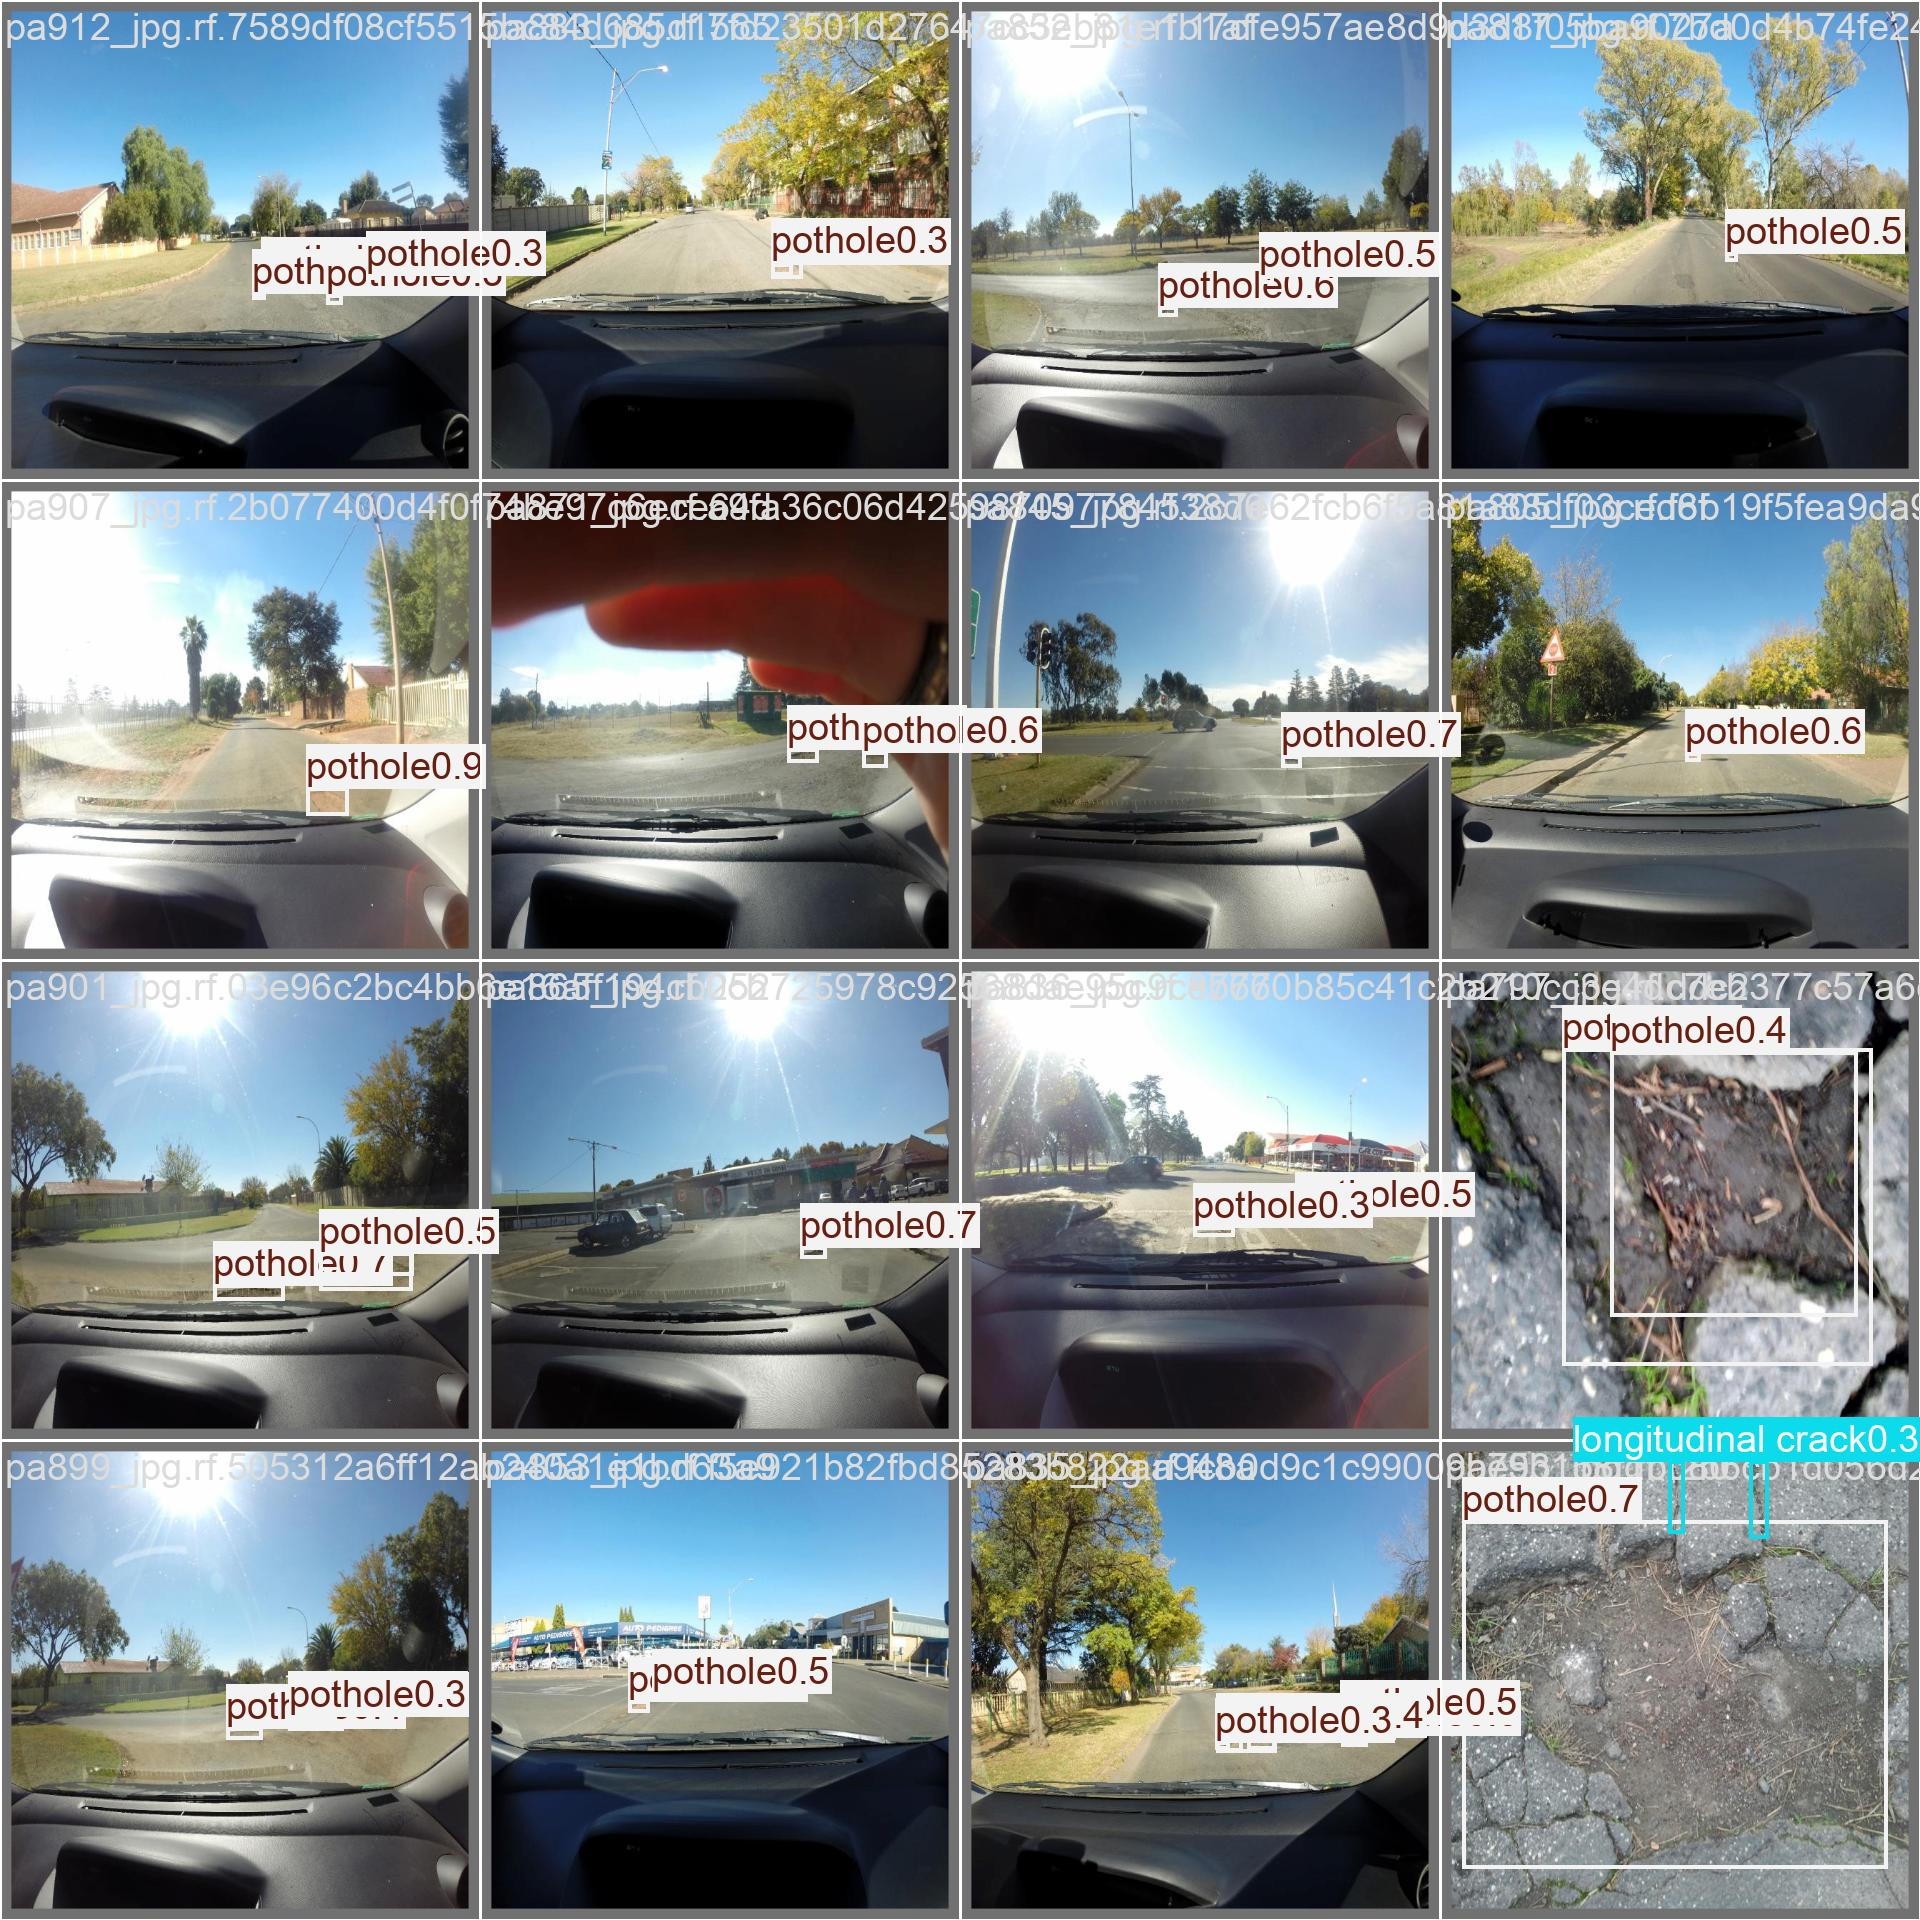

val_batch1_pred.jpg


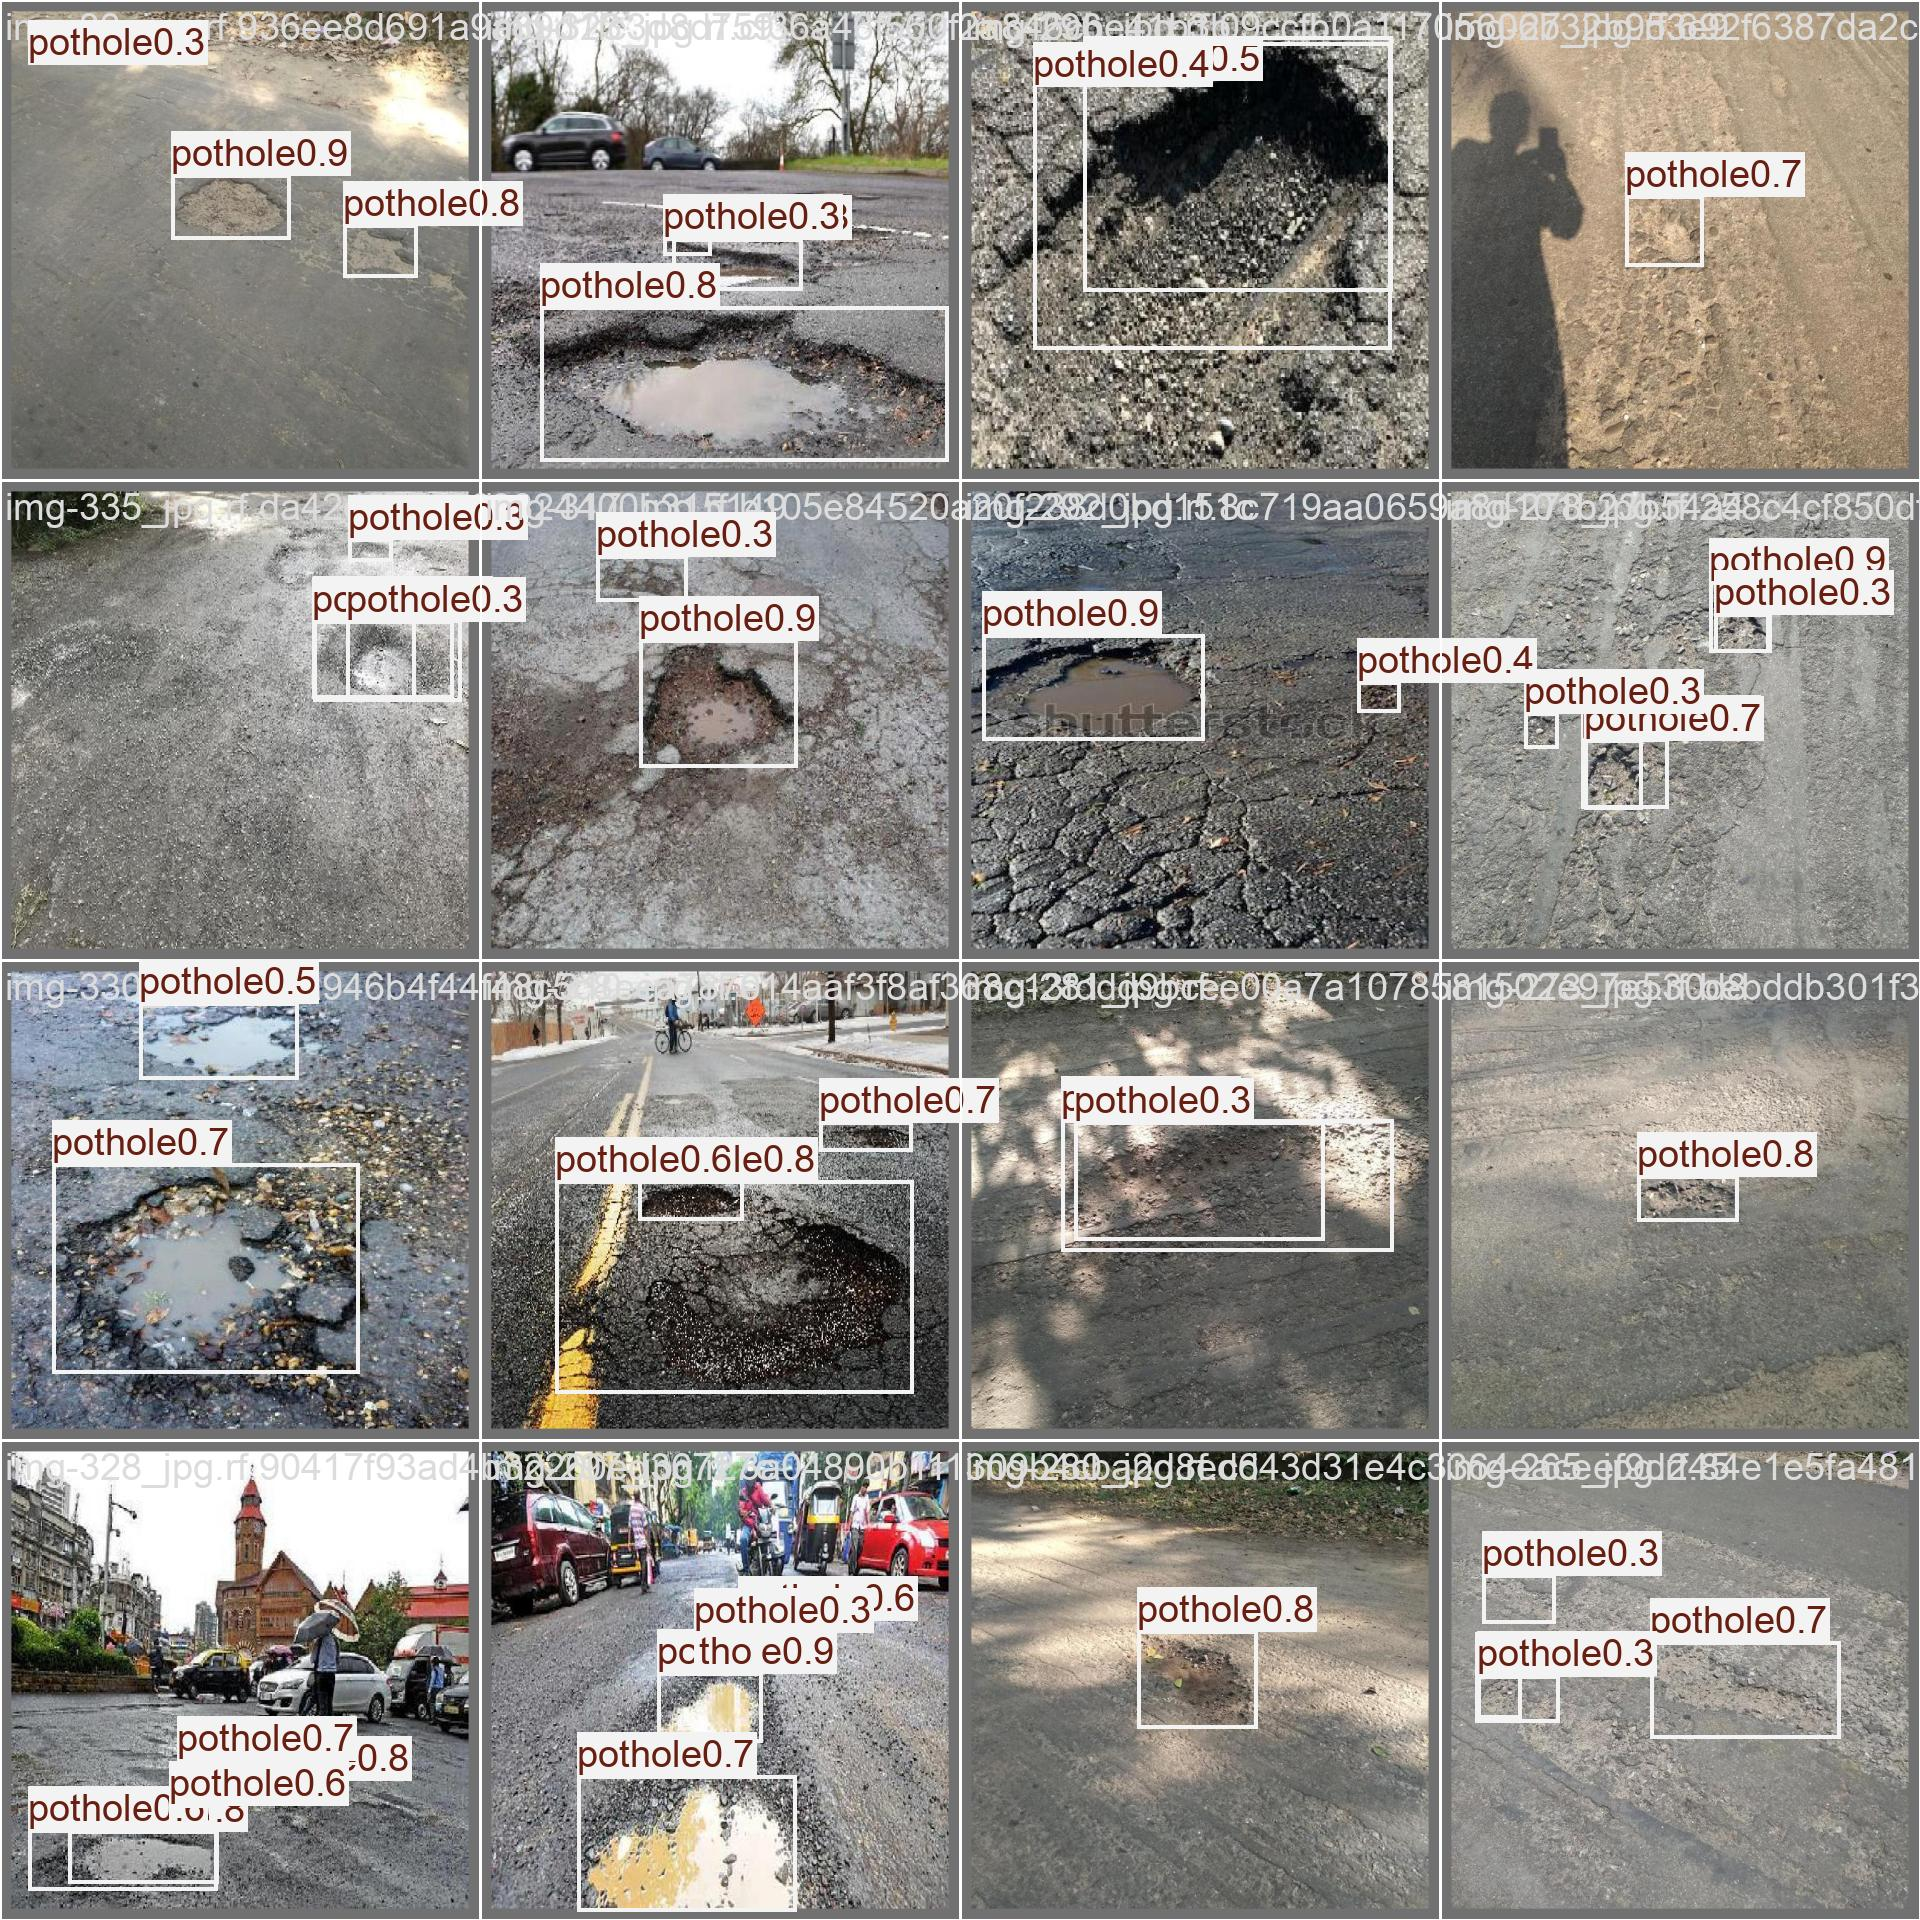

val_batch2_pred.jpg


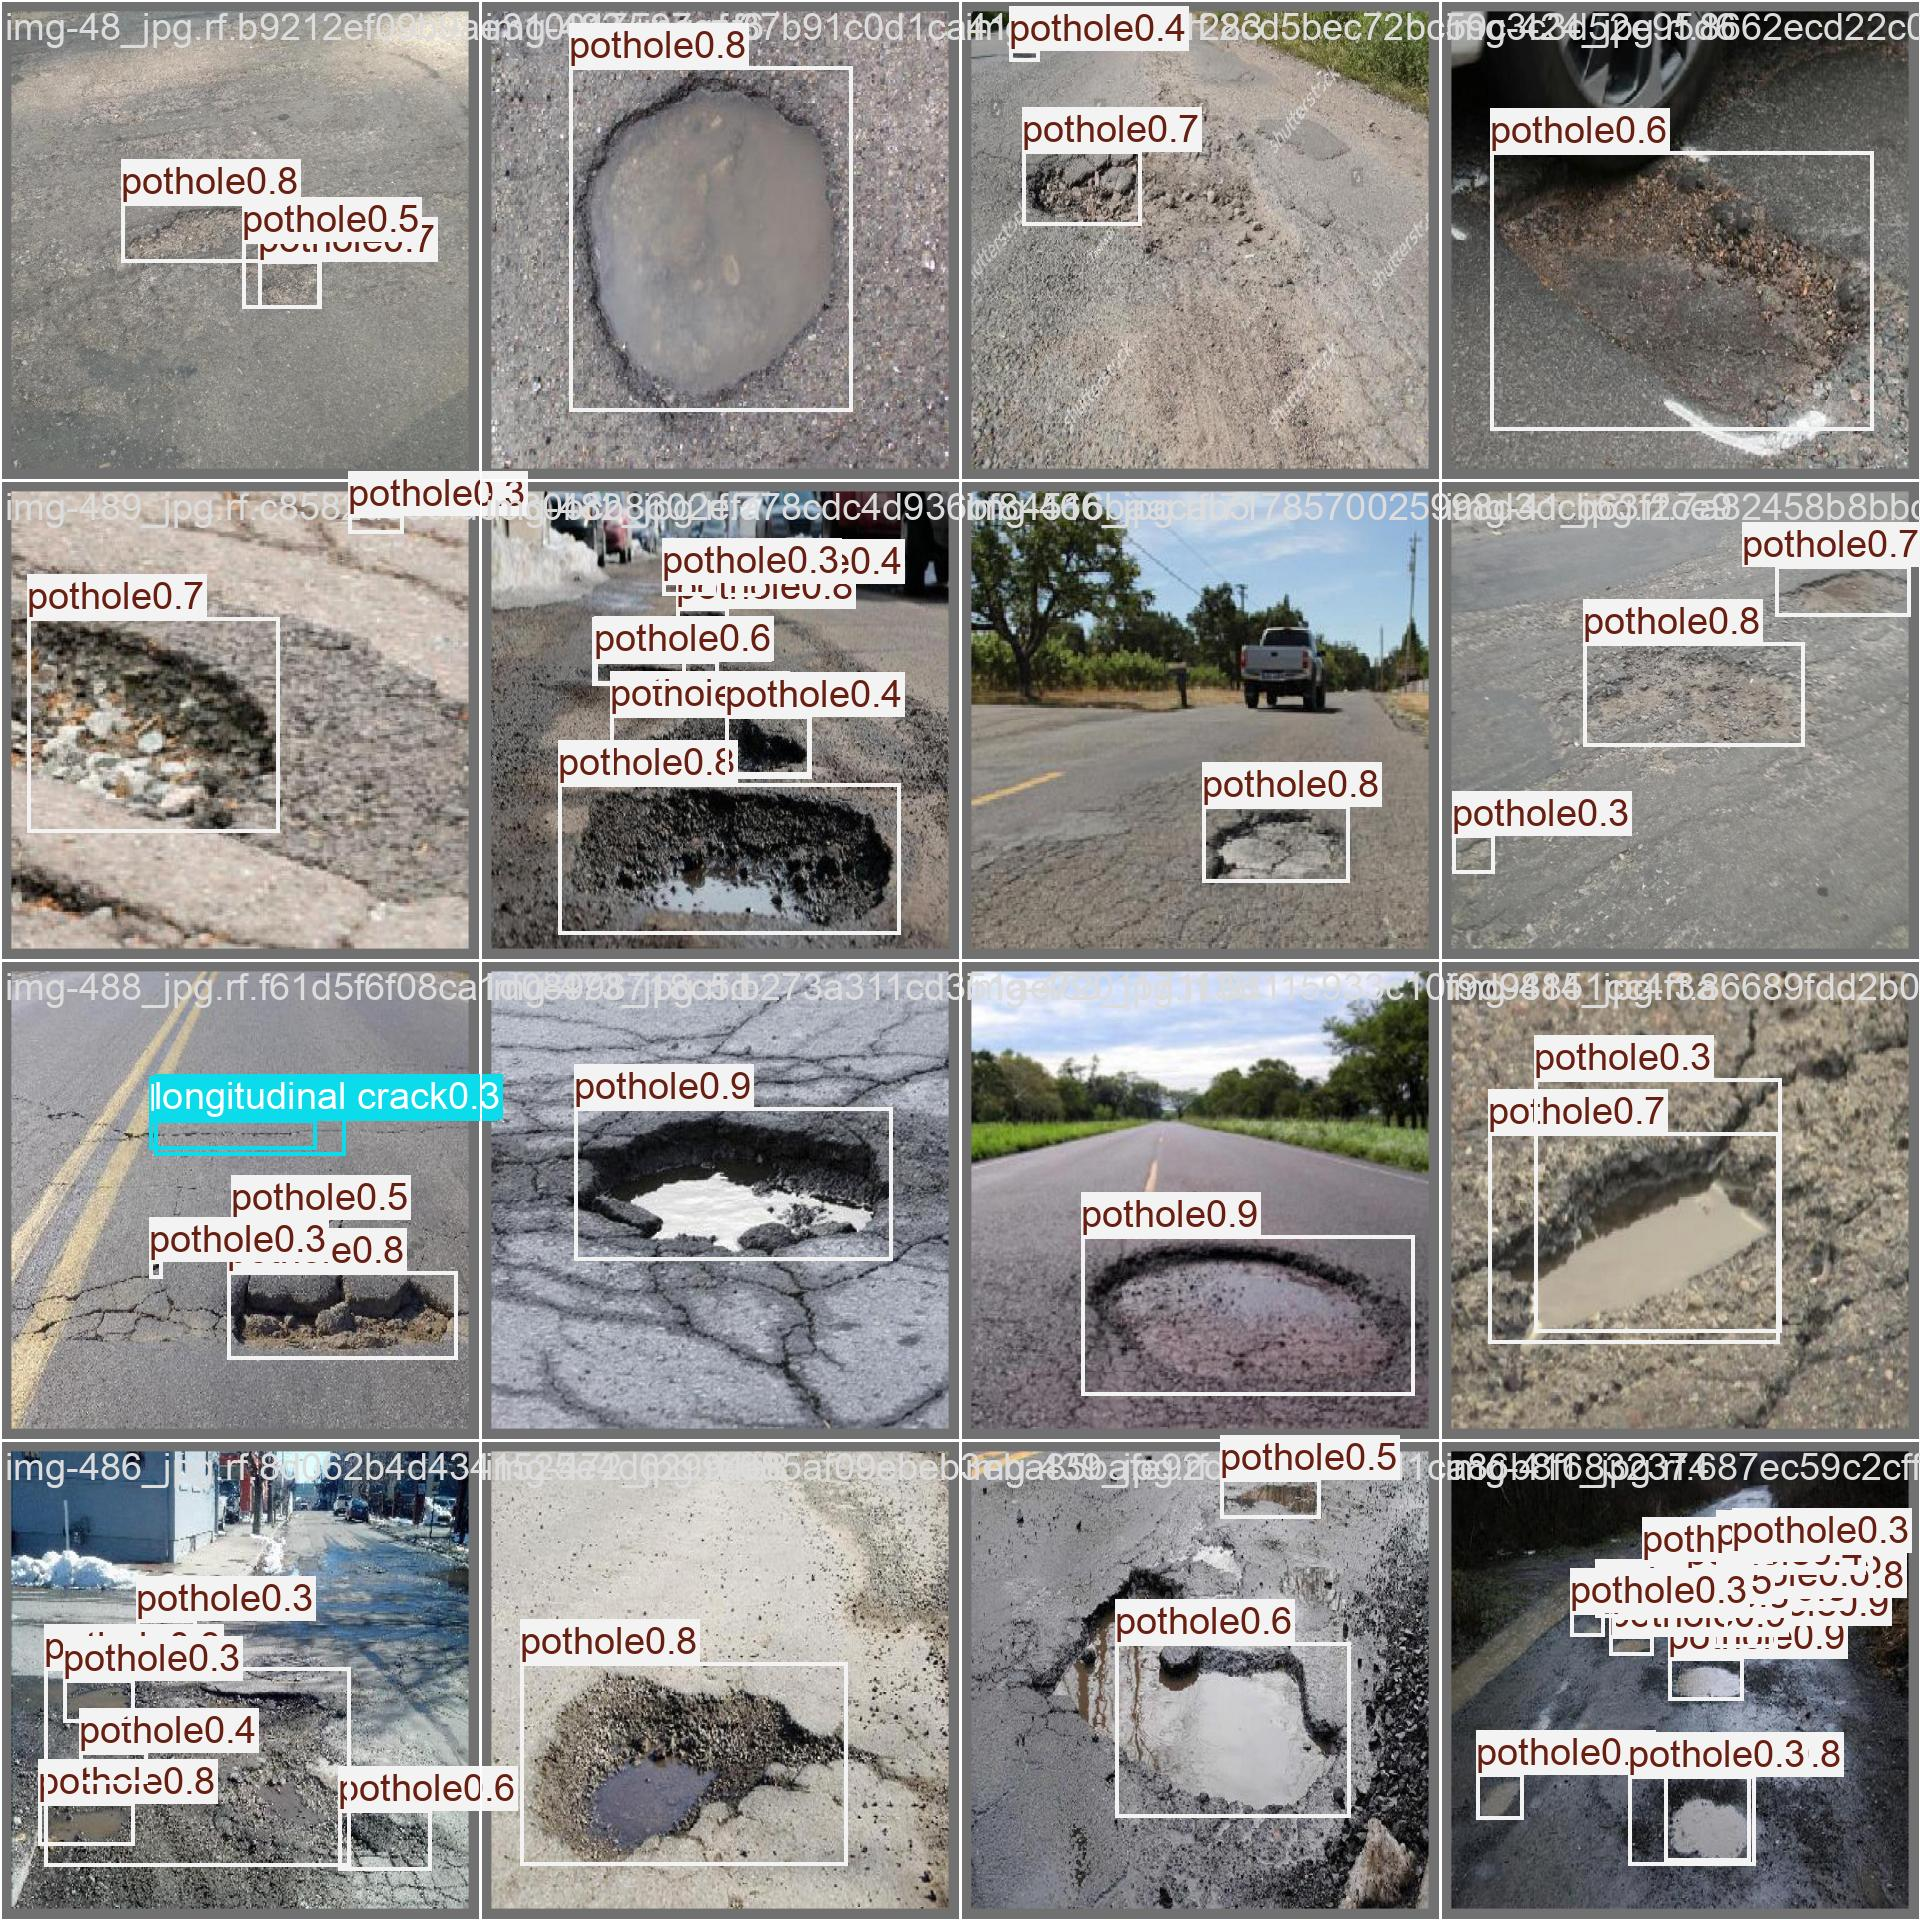

In [5]:
from pathlib import Path
from IPython.display import display, Image

results_dir = Path(
    r"C:\Users\Shikhaj Somani\OneDrive\Desktop\Major Project\runs\detect\train-5"
)

for filename in [
    "val_batch0_pred.jpg",
    "val_batch1_pred.jpg",
    "val_batch2_pred.jpg"
]:
    path = results_dir / filename
    if path.exists():
        print(filename)
        display(Image(filename=str(path)))
    else:
        print(f"Not found: {path}")

val_batch0_labels.jpg


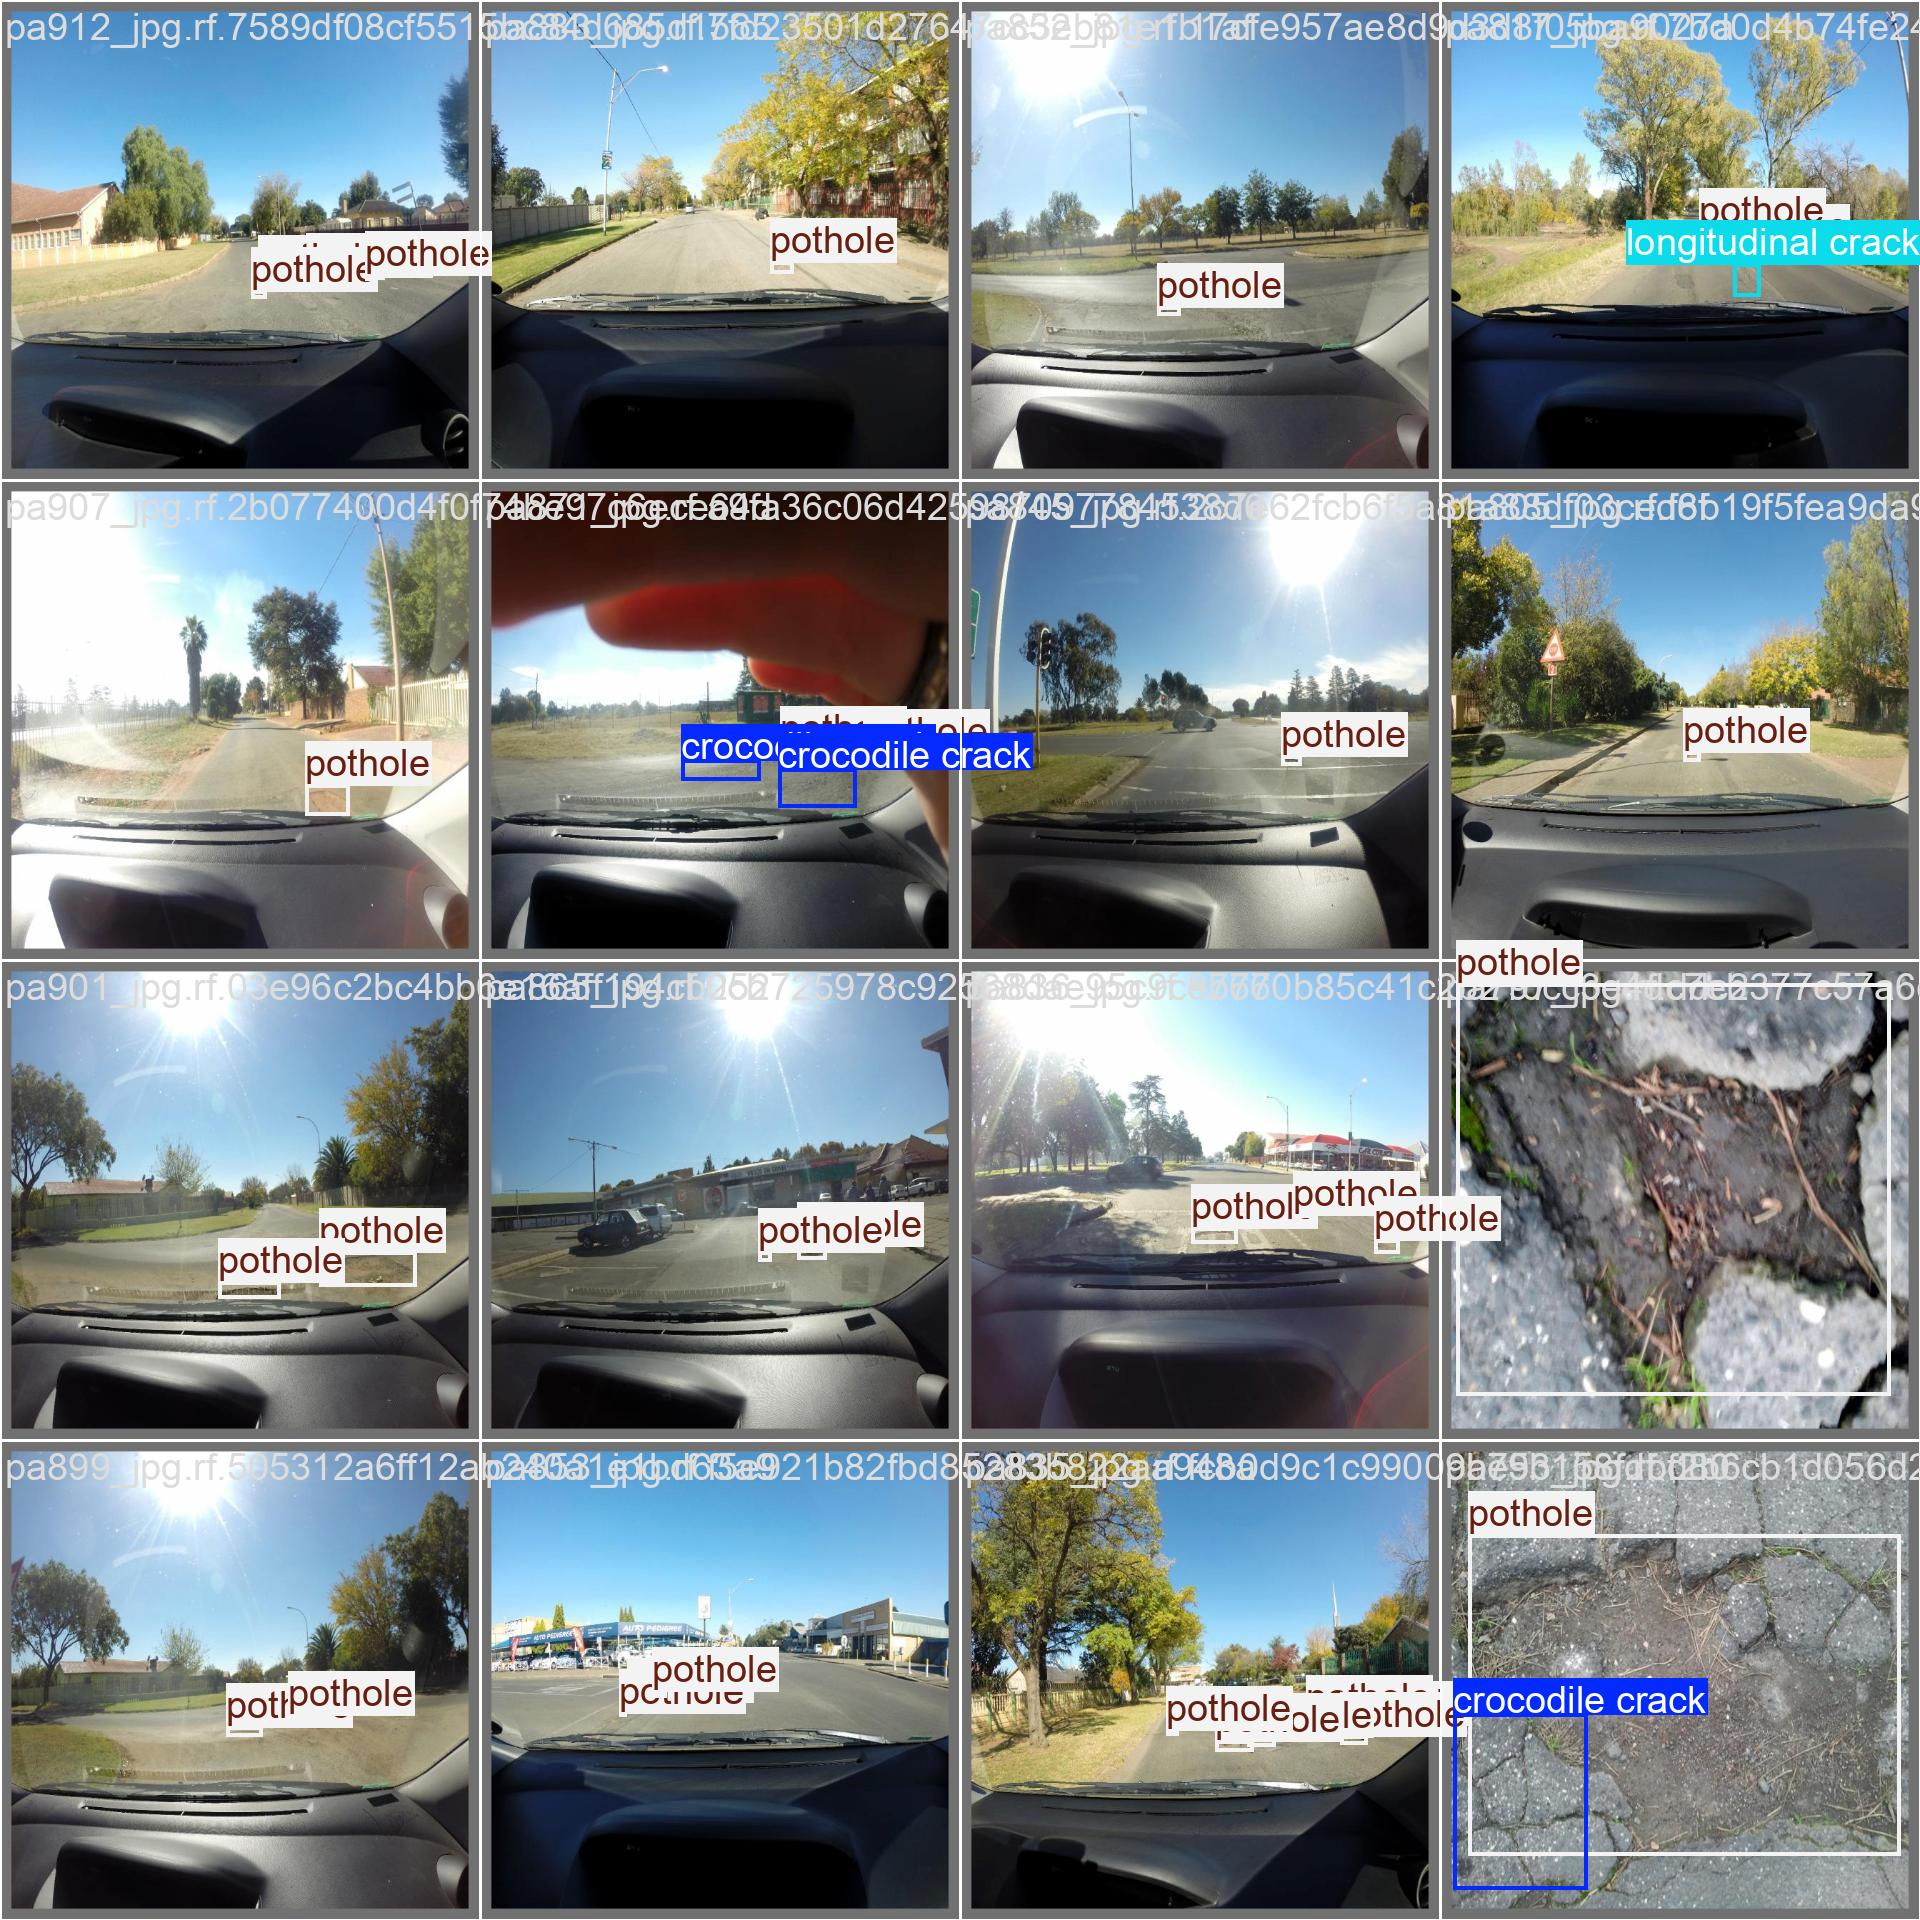

val_batch1_labels.jpg


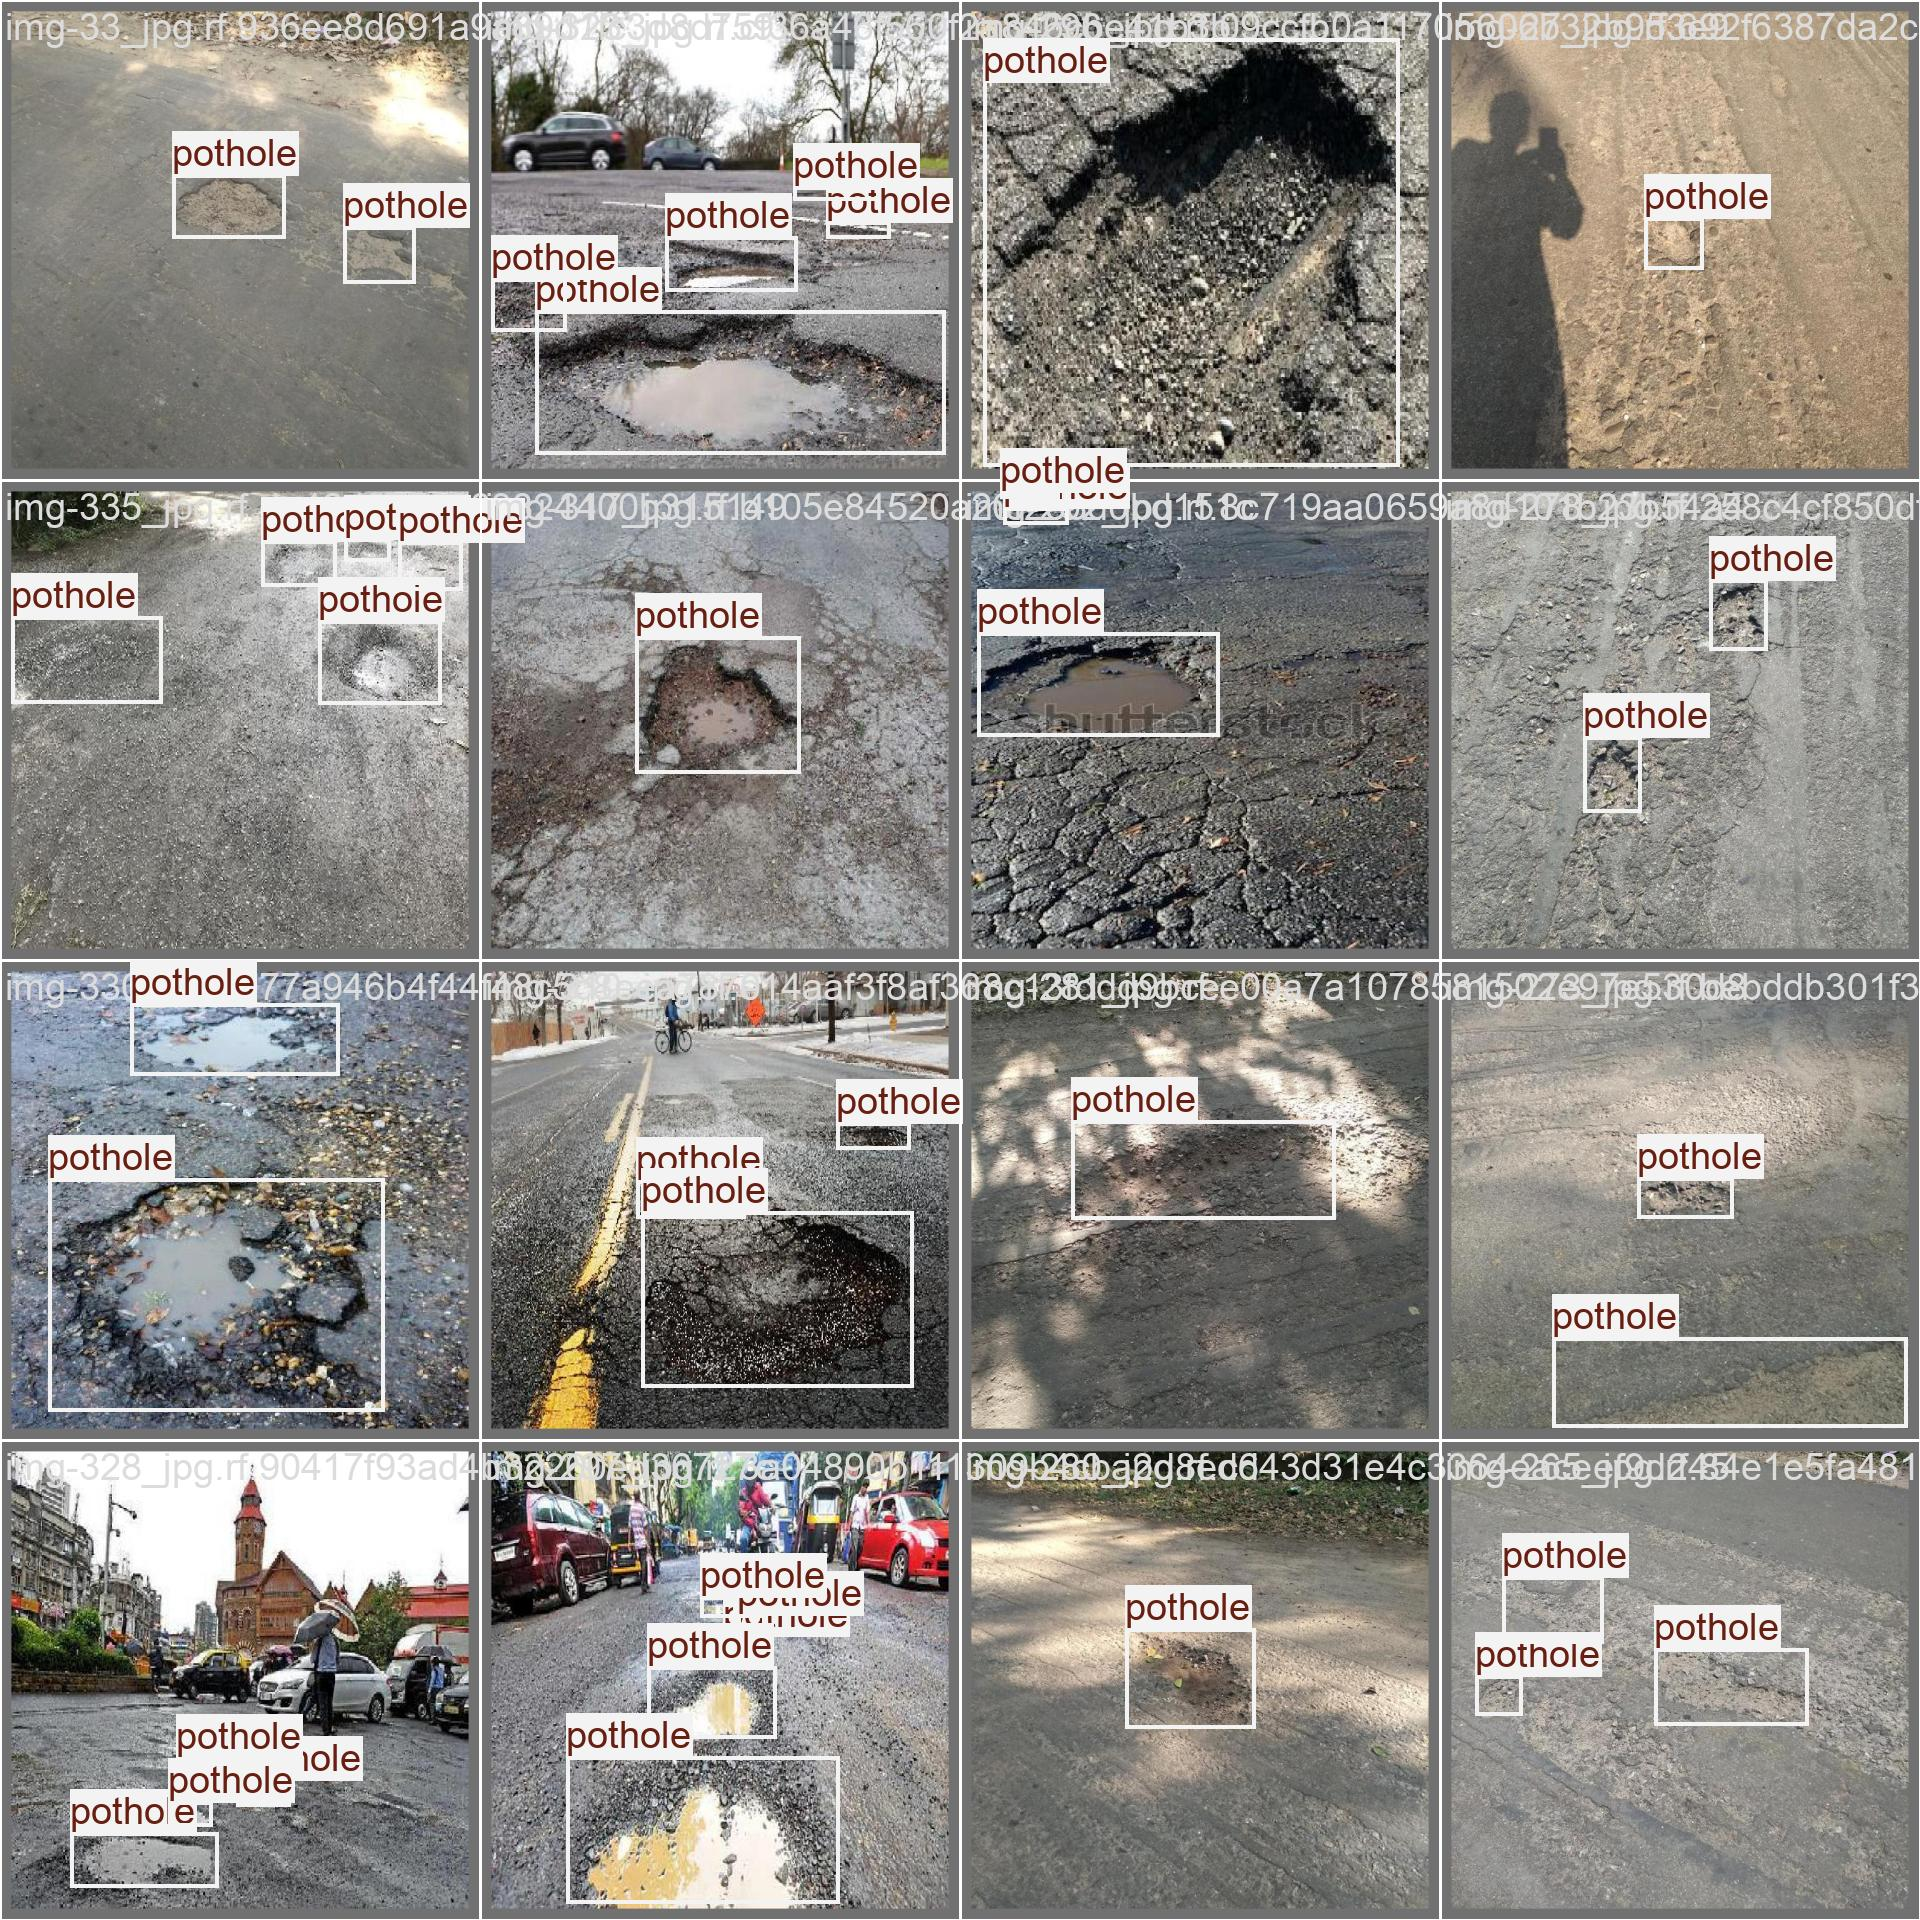

In [6]:
from pathlib import Path
from IPython.display import display, Image

label_dir = Path(
    r"C:\Users\Shikhaj Somani\OneDrive\Desktop\Major Project\runs\detect\train-5"
)

for filename in ["val_batch0_labels.jpg", "val_batch1_labels.jpg"]:
    path = label_dir / filename

    if path.exists():
        print(filename)
        display(Image(filename=str(path)))
    else:
        print(f"Not found: {path}")

In [7]:
from pathlib import Path

dataset_dir = Path("Pothole-detection-1")
images_dir = dataset_dir / "valid" / "images"
labels_dir = dataset_dir / "valid" / "labels"

for image_path in list(images_dir.glob("*"))[:10]:
    label_path = labels_dir / f"{image_path.stem}.txt"

    print(
        "Image:", image_path.name,
        "| Label exists:", label_path.exists(),
        "| Label file:", label_path.name
    )

Image: img-108_jpg.rf.8c144a56a41a5edfd25aabf47d7fcc14.jpg | Label exists: True | Label file: img-108_jpg.rf.8c144a56a41a5edfd25aabf47d7fcc14.txt
Image: img-116_jpg.rf.626b2a41e61bce3623def723244c008b.jpg | Label exists: True | Label file: img-116_jpg.rf.626b2a41e61bce3623def723244c008b.txt
Image: img-121_jpg.rf.335759536e2a7f6fa376fc19ad02a78e.jpg | Label exists: True | Label file: img-121_jpg.rf.335759536e2a7f6fa376fc19ad02a78e.txt
Image: img-122_jpg.rf.3c10fca1dd5fe37b5fedc7943b53f4f7.jpg | Label exists: True | Label file: img-122_jpg.rf.3c10fca1dd5fe37b5fedc7943b53f4f7.txt
Image: img-145_jpg.rf.e26723de7db126e43d82f8842ebdcced.jpg | Label exists: True | Label file: img-145_jpg.rf.e26723de7db126e43d82f8842ebdcced.txt
Image: img-146_jpg.rf.362695d227ce7f67ce617d3addb5169d.jpg | Label exists: True | Label file: img-146_jpg.rf.362695d227ce7f67ce617d3addb5169d.txt
Image: img-149_jpg.rf.eb867fd6890fcf6dc21127a06054343c.jpg | Label exists: True | Label file: img-149_jpg.rf.eb867fd6890fcf6

In [8]:
from pathlib import Path
from collections import Counter

labels_dir = Path("Pothole-detection-1/valid/labels")

class_names = {
    0: "crocodile crack",
    1: "longitudinal crack",
    2: "pothole"
}

class_counts = Counter()
empty_labels = []
invalid_labels = []

for label_file in labels_dir.glob("*.txt"):
    lines = label_file.read_text().strip().splitlines()

    if not lines:
        empty_labels.append(label_file.name)
        continue

    for line in lines:
        parts = line.split()

        try:
            class_id = int(parts[0])
            values = [float(x) for x in parts[1:]]

            if class_id not in class_names or len(values) != 4:
                invalid_labels.append((label_file.name, line))
                continue

            x_center, y_center, width, height = values

            if not (
                0 <= x_center <= 1
                and 0 <= y_center <= 1
                and 0 < width <= 1
                and 0 < height <= 1
            ):
                invalid_labels.append((label_file.name, line))
                continue

            class_counts[class_id] += 1

        except (ValueError, IndexError):
            invalid_labels.append((label_file.name, line))

print("Validation annotation counts:")
for class_id, name in class_names.items():
    print(f"{name}: {class_counts[class_id]}")

print("Empty label files:", len(empty_labels))
print("Invalid annotations:", len(invalid_labels))
print("Total label files:", len(list(labels_dir.glob("*.txt"))))

if invalid_labels:
    print("\nExamples of invalid annotations:")
    print(invalid_labels[:5])

Validation annotation counts:
crocodile crack: 125
longitudinal crack: 284
pothole: 1444
Empty label files: 0
Invalid annotations: 0
Total label files: 542


In [9]:
from ultralytics import YOLO

model = YOLO(
    r"C:\Users\Shikhaj Somani\OneDrive\Desktop\Major Project\runs\detect\train-5\weights\best.pt"
)

print("Best epoch:", model.ckpt.get("epoch", "Not available") + 1)

Best epoch: 0


In [10]:
import pandas as pd
from pathlib import Path

csv_path = Path(
    r"C:\Users\Shikhaj Somani\OneDrive\Desktop\Major Project\runs\detect\train-5\results.csv"
)

df = pd.read_csv(csv_path)
df.columns = df.columns.str.strip()

metric = "metrics/mAP50-95(B)"
best_idx = df[metric].idxmax()

print("Best epoch:", int(best_idx) + 1)
print("Best overall mAP50-95:", round(df.loc[best_idx, metric], 4))

Best epoch: 14
Best overall mAP50-95: 0.1379


In [11]:

from pathlib import Path
import shutil
import yaml

# Original dataset
SOURCE = Path("Pothole-detection-1")

# New dataset — original remains untouched
DEST = Path("Pothole-only")

# Class ID 2 in the original dataset is pothole
POTHOLE_CLASS_ID = 2

for split in ["train", "valid", "test"]:
    source_images = SOURCE / split / "images"
    source_labels = SOURCE / split / "labels"

    dest_images = DEST / split / "images"
    dest_labels = DEST / split / "labels"

    dest_images.mkdir(parents=True, exist_ok=True)
    dest_labels.mkdir(parents=True, exist_ok=True)

    for image_path in source_images.iterdir():
        if not image_path.is_file():
            continue

        label_path = source_labels / f"{image_path.stem}.txt"

        # Copy the image
        shutil.copy2(image_path, dest_images / image_path.name)

        # Retain only pothole annotations and remap class 2 -> 0
        pothole_lines = []

        if label_path.exists():
            for line in label_path.read_text().splitlines():
                parts = line.split()

                if len(parts) == 5 and int(parts[0]) == POTHOLE_CLASS_ID:
                    parts[0] = "0"
                    pothole_lines.append(" ".join(parts))

        # Empty labels are allowed: these images have no potholes
        (dest_labels / f"{image_path.stem}.txt").write_text(
            "\n".join(pothole_lines)
        )

# Create a new YOLO dataset configuration
config = {
    "path": str(DEST.resolve()),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 1,
    "names": ["pothole"]
}

(DEST / "data.yaml").write_text(
    yaml.safe_dump(config, sort_keys=False)
)

print("Pothole-only dataset created at:", DEST.resolve())
print("Classes:", config["names"])


Pothole-only dataset created at: C:\Users\Shikhaj Somani\OneDrive\Desktop\mjr prj\civicbridge\backend\Pothole-only
Classes: ['pothole']


In [12]:
from pathlib import Path
import yaml

dataset = Path("Pothole-only")
config = yaml.safe_load((dataset / "data.yaml").read_text())

print("Configuration:", config)

for split in ["train", "valid", "test"]:
    images = list((dataset / split / "images").glob("*"))
    labels = list((dataset / split / "labels").glob("*.txt"))

    pothole_boxes = sum(
        1
        for label in labels
        for line in label.read_text().splitlines()
        if line.strip()
    )

    print(
        f"{split}: {len(images)} images, "
        f"{len(labels)} label files, {pothole_boxes} pothole boxes"
    )

Configuration: {'path': 'C:\\Users\\Shikhaj Somani\\OneDrive\\Desktop\\mjr prj\\civicbridge\\backend\\Pothole-only', 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images', 'nc': 1, 'names': ['pothole']}
train: 1906 images, 1906 label files, 5149 pothole boxes
valid: 542 images, 542 label files, 1444 pothole boxes
test: 274 images, 274 label files, 677 pothole boxes


In [13]:

from ultralytics import YOLO
from pathlib import Path
import torch

DATA_YAML = Path("Pothole-only/data.yaml").resolve()

print("CUDA available:", torch.cuda.is_available())
print("Dataset:", DATA_YAML)

model = YOLO("yolov8n.pt")

results = model.train(
    data=str(DATA_YAML),
    epochs=50,
    imgsz=640,
    batch=8,
    workers=0,
    device=0 if torch.cuda.is_available() else "cpu",
    patience=15,
    project="runs/detect",
    name="pothole_only_50",
    plots=True,
    seed=42
)


CUDA available: True
Dataset: C:\Users\Shikhaj Somani\OneDrive\Desktop\mjr prj\civicbridge\backend\Pothole-only\data.yaml
Ultralytics 8.4.185  Python-3.10.22 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\Shikhaj Somani\OneDrive\Desktop\mjr prj\civicbridge\backend\Pothole-only\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_wi

In [14]:
from ultralytics import YOLO
from pathlib import Path

model_path = Path(
    r"C:\Users\Shikhaj Somani\OneDrive\Desktop\Major Project"
    r"\runs\detect\runs\detect\pothole_only_50\weights\best.pt"
)

data_yaml = Path("Pothole-only/data.yaml").resolve()

model = YOLO(str(model_path))

test_results = model.val(
    data=str(data_yaml),
    split="test",
    imgsz=640,
    batch=8,
    workers=0,
    plots=True,
    project="runs/detect",
    name="pothole_only_test"
)

print("Test Precision:", test_results.box.mp)
print("Test Recall:", test_results.box.mr)
print("Test mAP50:", test_results.box.map50)
print("Test mAP50-95:", test_results.box.map)

Ultralytics 8.4.185  Python-3.10.22 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
WARNING val: Slow image access detected (ping: 0.6±0.4 ms, read: 4.8±3.2 MB/s, size: 58.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\Shikhaj Somani\OneDrive\Desktop\mjr prj\civicbridge\backend\Pothole-only\test\labels... 274 images, 4 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 274/274 353.7it/s 0.8s0.0s
val: New cache created: C:\Users\Shikhaj Somani\OneDrive\Desktop\mjr prj\civicbridge\backend\Pothole-only\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 8.6it/s 4.1s0.2ss
                   all        274        677      0.691      0.594      0.648      0.342
Speed: 0.5ms preprocess, 5.5ms inference, 

In [15]:
from pathlib import Path
from ultralytics import YOLO

model_path = Path(
    r"C:\Users\Shikhaj Somani\OneDrive\Desktop\Major Project"
    r"\runs\detect\runs\detect\pothole_only_50\weights\best.pt"
)

data_yaml = Path("Pothole-only/data.yaml").resolve()

model = YOLO(str(model_path))

# Evaluate on validation data and generate diagnostic plots
model.val(
    data=str(data_yaml),
    split="val",
    imgsz=640,
    batch=8,
    workers=0,
    plots=True,
    project="runs/detect",
    name="pothole_validation_review"
)

# Generate predictions at a low threshold to inspect potential misses
model.predict(
    source=str(Path("Pothole-only/valid/images").resolve()),
    conf=0.10,
    imgsz=640,
    batch=8,
    save=True,
    project="runs/detect",
    name="pothole_validation_predictions"
)

Ultralytics 8.4.185  Python-3.10.22 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
WARNING val: Slow image access detected (ping: 0.3±0.0 ms, read: 7.9±2.9 MB/s, size: 61.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\Shikhaj Somani\OneDrive\Desktop\mjr prj\civicbridge\backend\Pothole-only\valid\labels.cache... 542 images, 9 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 542/542  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 68/68 4.4it/s 15.5s0.2s
                   all        542       1444      0.718      0.577      0.653       0.34
Speed: 0.4ms preprocess, 8.3ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to C:\Users\Shikhaj Somani\OneDrive\Desktop\Major Project\runs\detect\runs\d

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: None
 names: {0: 'pothole'}
 obb: None
 orig_img: array([[[171, 183, 183],
         [155, 167, 167],
         [172, 184, 184],
         ...,
         [ 51,  78,  69],
         [ 29,  58,  49],
         [ 74, 103,  94]],
 
        [[191, 203, 203],
         [176, 188, 188],
         [178, 190, 190],
         ...,
         [ 31,  58,  49],
         [ 59,  88,  79],
         [ 86, 115, 106]],
 
        [[167, 179, 179],
         [182, 194, 194],
         [186, 198, 198],
         ...,
         [ 59,  86,  77],
         [ 87, 116, 107],
         [ 49,  78,  69]],
 
        ...,
 
        [[152, 169, 178],
         [134, 151, 160],
         [142, 159, 168],
         ...,
         [118, 130, 134],
         [111, 123, 127],
         [108, 120, 124]],
 
        [[153, 170, 179],
         [147, 164, 173],
         [134, 151, 160],
         ...,
    

In [1]:
import numpy as np

In [10]:
from ultralytics import YOLO

model = YOLO("best_pothole0.pt")

results = model.predict(
    source="download1.jpeg",
    conf=0.25,
    save=True
)


image 1/1 c:\Users\Shikhaj Somani\OneDrive\Desktop\mjr prj\civicbridge\backend\download1.jpeg: 640x640 1 longitudinal crack, 57.4ms
Speed: 5.2ms preprocess, 57.4ms inference, 5.0ms postprocess per image at shape (1, 3, 640, 640)
Results saved to C:\Users\Shikhaj Somani\OneDrive\Desktop\Major Project\runs\detect\predict-8


In [6]:
import os

os.listdir("C:/Users/Shikhaj Somani/OneDrive/Desktop/Major Project/runs/detect/predict-6")

['download1.jpg']

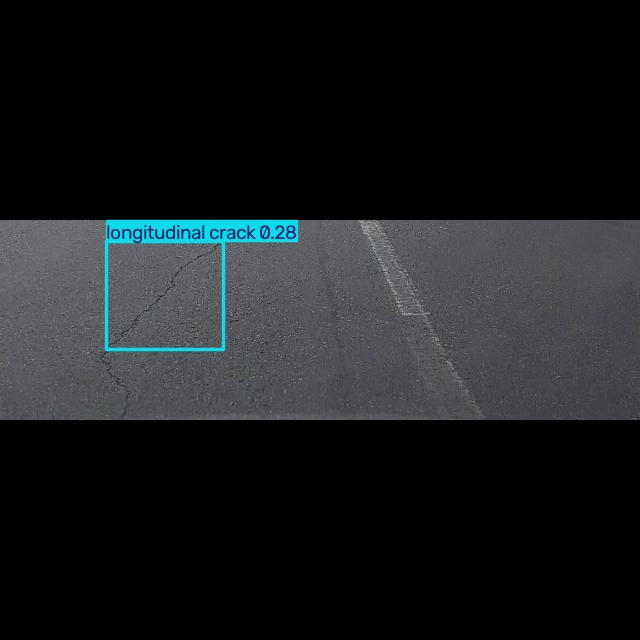

In [11]:
from IPython.display import Image

Image("C:/Users/Shikhaj Somani/OneDrive/Desktop/Major Project/runs/detect/predict-8/download1.jpg")

In [12]:
from ultralytics import YOLO
from pathlib import Path

model_path = "best_pothole0.pt"

data_yaml = Path("Pothole-detection-1/data.yaml").resolve()

model = YOLO(str(model_path))

test_results = model.val(
    data=str(data_yaml),
    split="test",
    imgsz=640,
    batch=8,
    workers=0,
    plots=True,
    project="runs/detect",
    name="pothole_only_test"
)

print("Test Precision:", test_results.box.mp)
print("Test Recall:", test_results.box.mr)
print("Test mAP50:", test_results.box.map50)
print("Test mAP50-95:", test_results.box.map)

Ultralytics 8.4.185  Python-3.10.22 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
WARNING val: Slow image access detected (ping: 0.6±0.1 ms, read: 7.9±3.0 MB/s, size: 87.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\Shikhaj Somani\OneDrive\Desktop\mjr prj\civicbridge\backend\Pothole-detection-1\test\labels... 274 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 274/274 465.2it/s 0.6s0.1s
val: New cache created: C:\Users\Shikhaj Somani\OneDrive\Desktop\mjr prj\civicbridge\backend\Pothole-detection-1\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 8.7it/s 4.0s0.1ss
                   all        274        861      0.357      0.345      0.313      0.137
       crocodile crack      